# CBIS-DDSM Combined Classifier v4: Single-View vs Dual-View vs Multi-Task
### Three models, one shared split, comparative analysis, Grad-CAM — PyTorch, Google Colab

### What changed vs v3, and an honest expectation-setting note
The v3 run landed at: A-CC 71.0%/0.764 AUC, A-MLO 72.2%/0.769, B (dual-view) 71.4%/0.772,
C (MTL) 74.5%/0.787, weighted ensemble 74.9%/0.804. That's three separate rounds of
hyperparameter tuning (augmentation, unfreezing depth, loss weights, TTA, ensemble
weighting) all converging to the **same ~0.76–0.80 AUC / ~71–75% accuracy band**,
regardless of architecture. That consistency is itself diagnostic: Model B's own logs show
train AUC reaching 0.89 while val AUC has flatlined at 0.76 for 15+ straight epochs — a
stable train/val gap that more epochs don't close. That's classic small-dataset
**overfitting/variance**, not a remaining hyperparameter to find. Three rounds of knob-turning
already explored that space.

**Target-setting honesty**: getting to 90% accuracy on a 231-sample held-out test set from
~1,100–3,200 training images is an ambitious ask — most published CBIS-DDSM results in that
range use larger effective training sets or mammography-pretrained backbones, not ImageNet
ResNet50 fine-tuned on ~1k pairs. This version applies the most legitimate structural fix for
the *specific* symptom observed (high variance from a single fragile split), but it is not
guaranteed to land at exactly 90% — if it still falls short, the credible next lever is more
data or a domain-pretrained backbone, not further hyperparameter tuning.

### The fix: patient-grouped k-fold bagging (replaces single 70/15 training)
Every model (A-CC, A-MLO, B, C) now trains **`N_BAG_FOLDS` (default 5) independently-split
models** instead of one, using `StratifiedGroupKFold` over the pooled train+val patients
(the held-out test set is never touched by any fold's training). Final predictions are the
**average across all fold models** (bagging directly reduces the variance we're seeing), and
the decision threshold is tuned on true **out-of-fold** predictions covering the whole pool
— not a small, noisy 220-sample validation slice. This is ~5x more training compute for the
bagged sections; set `RUN_BAGGED_ENSEMBLE = False` to fall back to the fast single-split
version from v3 if you just want to sanity-check the pipeline first.

This notebook merges the three earlier notebooks (`CBIS_DDSM_DualView_Classifier`, `_v2`,
`_v3_MTL_CV`) into a single pipeline that trains **three model families one after another on
the same data and the same patient-level held-out test set**, so the final comparison is
apples-to-apples:

| # | Model | Source notebook | What it is |
|---|---|---|---|
| A | **Single-view baseline** | v1/v2/v3 "Step 11" | Two separate ResNet50 classifiers, one on CC-only crops, one on MLO-only crops |
| B | **Dual-view cross-attention** | v1 / v2 | Weight-shared ResNet50 encoders for CC+MLO, fused with a cross-view attention block, single malignancy head |
| C | **Dual-view multi-task (MTL)** | v3 | Same cross-attention fusion as B, plus auxiliary heads for breast density, subtlety, and abnormality type (mass vs. calcification), trained with a combined Focal + auxiliary-CE loss |

After all three are trained it builds an **ensemble** (average of A-CC, A-MLO, and the better
of B/C), a **comparative analysis table + chart**, and finally **Grad-CAM** on the
best-performing model.

### Key change from the earlier notebooks: cropped images, not full mammograms
The earlier notebooks paired the **full mammogram** image per breast side. This version
pairs the **cropped ROI image** per *abnormality* instead (CBIS-DDSM's own CSVs already
give each abnormality its own CC and MLO cropped image) — this is the ~10,000-image
cropped-image collection referenced by the SeriesDescription `cropped images` in
`dicom_info.csv`. Cropped ROI images are a substantially easier classification target
than full mammograms (the lesion already fills the frame), which is why this pipeline
targets **80–95% accuracy** — full-mammogram dual-view models in the earlier notebooks
were realistically closer to 65–80%.

> **Run cells top to bottom in Colab. Runtime → Change runtime type → T4 GPU.**
> This notebook cannot be executed outside Colab (no GPU / no dataset access here) —
> treat the epoch counts and architecture choices below as a well-documented starting
> point, not a guarantee; the real numbers are whatever your run produces.

### Config you'll actually want to touch
- `USE_FULL_DATASET` — `True` uses all ~10k cropped images; set `False` + `SAMPLE_FRACTION`
  for a quick smoke-test run before committing to the full training time.
- `RUN_BAGGED_ENSEMBLE` — `True` (default, v4) trains `N_BAG_FOLDS` models per architecture
  and bags them, ~5x the compute of a single split. Set `False` to fall back to v3's fast
  single-split training if you just want to sanity-check the pipeline runs end to end first.


## Step 0 — Config

In [ ]:
USE_FULL_DATASET = True     # False -> subsample with SAMPLE_FRACTION for a fast smoke test
SAMPLE_FRACTION   = 0.35    # only used when USE_FULL_DATASET is False
RANDOM_STATE      = 42
IMG_SIZE          = 224     # crops are already zoomed in, 224 is enough and trains faster than 288
BATCH_SIZE        = 48      # bumped from 32 - crops are small, more headroom in GPU memory
ACCUM_STEPS       = 1       # crops are smaller than full mammograms -> larger physical batch fits fine

# --- v2: training-budget fixes (see diagnosis above) ---
UNFREEZE_PREFIXES  = ['layer2', 'layer3', 'layer4']  # was ['layer3', 'layer4'] - more of the
                                                       # backbone gets to adapt to mammograms
DUAL_PHASE1_EPOCHS = 2    # was 3-4; head warm-up doesn't need to be long
DUAL_PHASE2_EPOCHS = 30   # was 15-20; the previous run was still improving at cutoff
DUAL_PATIENCE       = 8   # was 4-5; give the longer schedule room to actually plateau
SINGLE_VIEW_EPOCHS  = 20  # was 12-15

# --- v4: patient-grouped k-fold bagging (see diagnosis above: train/val AUC gap that
# more epochs don't close = variance from one fragile split, not a hyperparameter gap) ---
RUN_BAGGED_ENSEMBLE = True   # False -> fall back to v3's single 70/15 split (fast, for smoke-testing)
N_BAG_FOLDS         = 5      # ~5x training compute for A/B/C when True


## Step 1 — Get your Kaggle API token
1. Go to https://www.kaggle.com/settings → **API** → **Create New Token**. This downloads `kaggle.json`.
2. Run the cell below, click **Choose Files**, and upload that `kaggle.json`.

In [ ]:
import os
import zipfile
from google.colab import files

!pip install -q kaggle
print("Kaggle Installation completed")


Kaggle Installation completed


## Step 2 — Download CBIS-DDSM directly into Colab
`awsaf49/cbis-ddsm-breast-cancer-image-dataset`

In [ ]:
DATA_DIR = '/content/cbis-ddsm'
os.makedirs(DATA_DIR, exist_ok=True)

!kaggle datasets download -d awsaf49/cbis-ddsm-breast-cancer-image-dataset -p {DATA_DIR} --unzip
!ls {DATA_DIR}


Dataset URL: https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
License(s): CC-BY-SA-3.0
100% 4.95G/4.95G [03:54<00:00, 22.6MB/s]

csv  jpeg


## Step 3 — Inspect what you actually got
Same principle as the source notebooks: regenerate every count from the files you actually
downloaded, never trust numbers copied from a template. This also confirms the
`cropped images` SeriesDescription and roughly how many crop files exist.

In [ ]:
import pandas as pd

csv_dir = f'{DATA_DIR}/csv'
print('CSV files found:', os.listdir(csv_dir))

mass_train = pd.read_csv(f'{csv_dir}/mass_case_description_train_set.csv')
mass_test  = pd.read_csv(f'{csv_dir}/mass_case_description_test_set.csv')
calc_train = pd.read_csv(f'{csv_dir}/calc_case_description_train_set.csv')
calc_test  = pd.read_csv(f'{csv_dir}/calc_case_description_test_set.csv')
dicom_info = pd.read_csv(f'{csv_dir}/dicom_info.csv')

print('Mass train/test cases:', len(mass_train), len(mass_test))
print('Calc train/test cases:', len(calc_train), len(calc_test))
print()
print('Pathology label distribution (mass, train):')
print(mass_train['pathology'].value_counts())
print()
print('Pathology label distribution (calc, train):')
print(calc_train['pathology'].value_counts())
print()
print('Image views available:', mass_train['image view'].unique())
print('SeriesDescription values in dicom_info.csv:', dicom_info['SeriesDescription'].unique())
print('Row count per SeriesDescription:')
print(dicom_info['SeriesDescription'].value_counts())


CSV files found: ['calc_case_description_train_set.csv', 'mass_case_description_test_set.csv', 'dicom_info.csv', 'mass_case_description_train_set.csv', 'meta.csv', 'calc_case_description_test_set.csv']
Mass train/test cases: 1318 378
Calc train/test cases: 1546 326

Pathology label distribution (mass, train):
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64

Pathology label distribution (calc, train):
pathology
MALIGNANT                  544
BENIGN                     528
BENIGN_WITHOUT_CALLBACK    474
Name: count, dtype: int64

Image views available: ['CC' 'MLO']
SeriesDescription values in dicom_info.csv: ['cropped images' 'full mammogram images' nan 'ROI mask images']
Row count per SeriesDescription:
SeriesDescription
cropped images           3567
ROI mask images          3247
full mammogram images    2857
Name: count, dtype: int64


## Step 4 — Build an abnormality-level, patient-split dataset of CROPPED images
Unlike the full-mammogram notebooks (which paired by breast side), cropped images are
per-**abnormality** — each row in the case CSVs already names one abnormality's CC/MLO
crop pair. We pair CC and MLO crops that belong to the **same abnormality id** on the
same breast, which is anatomically correct for ROI crops (a lesion's two views).

**Known quirk of this Kaggle release**: `dicom_info.csv` sometimes tags both the actual
cropped-lesion JPEG and its binary ROI mask JPEG as `cropped images` for the same case
folder (they were converted from the same source folder). Where a case_id has more than
one `cropped images` row, we keep the **larger file** — ROI masks are near-binary images
that compress much smaller than a real grayscale crop. Spot-check a few examples visually
after this step (Step 4b) before trusting it at scale.

In [ ]:
import re

def build_case_df(mass_dfs, calc_dfs):
    frames = []
    for df in mass_dfs:
        d = df.copy()
        d = d.rename(columns={'breast density': 'breast_density'})
        d['case_id'] = d['cropped image file path'].apply(lambda x: str(x).split('/')[0])
        d['origin'] = 'mass'
        frames.append(d[['patient_id', 'left or right breast', 'image view', 'pathology',
                          'abnormality id', 'case_id', 'origin', 'breast_density', 'subtlety']])
    for df in calc_dfs:
        d = df.copy()
        d = d.rename(columns={'breast density': 'breast_density'})
        d['case_id'] = d['cropped image file path'].apply(lambda x: str(x).split('/')[0])
        d['origin'] = 'calc'
        frames.append(d[['patient_id', 'left or right breast', 'image view', 'pathology',
                          'abnormality id', 'case_id', 'origin', 'breast_density', 'subtlety']])
    return pd.concat(frames, ignore_index=True)

case_df = build_case_df([mass_train, mass_test], [calc_train, calc_test])
case_df['label'] = (case_df['pathology'].str.upper() == 'MALIGNANT').astype(int)

# --- Resolve case_id -> actual cropped-image jpeg path, deduping mask-vs-crop ambiguity ---
crop_rows = dicom_info[dicom_info['SeriesDescription'] == 'cropped images'][
    ['PatientID', 'image_path']].rename(columns={'PatientID': 'case_id'})
crop_rows['image_path'] = crop_rows['image_path'].apply(
    lambda p: p.replace('CBIS-DDSM/jpeg', f'{DATA_DIR}/jpeg')
)

def pick_largest(paths):
    sizes = [(p, os.path.getsize(p)) for p in paths if os.path.exists(p)]
    if not sizes:
        return None
    return max(sizes, key=lambda t: t[1])[0]

crop_resolved = (crop_rows.groupby('case_id')['image_path']
                  .apply(lambda paths: pick_largest(list(paths)))
                  .reset_index())

case_df = case_df.merge(crop_resolved, on='case_id', how='left')
before = len(case_df)
case_df = case_df.dropna(subset=['image_path'])
print(f'Matched {len(case_df)}/{before} rows to an actual cropped-image file.')

# --- Auxiliary multi-task label encoding (used by Model C) ---
def encode_density(v):
    try:
        v = int(v)
        if 1 <= v <= 4:
            return v - 1
    except (ValueError, TypeError):
        pass
    return 4

def encode_subtlety(v):
    try:
        v = int(v)
        if 1 <= v <= 5:
            return v - 1
    except (ValueError, TypeError):
        pass
    return 5

case_df['density_label'] = case_df['breast_density'].apply(encode_density)
case_df['subtlety_label'] = case_df['subtlety'].apply(encode_subtlety)
case_df['type_label'] = (case_df['origin'] == 'calc').astype(int)

N_DENSITY_CLASSES, N_SUBTLETY_CLASSES, N_TYPE_CLASSES = 5, 6, 2

# --- Pair CC + MLO crops that share the same (patient, side, abnormality id) ---
pair_rows = []
for (pid, side, abn_id), grp in case_df.groupby(['patient_id', 'left or right breast', 'abnormality id']):
    cc_rows = grp[grp['image view'] == 'CC']
    mlo_rows = grp[grp['image view'] == 'MLO']
    if len(cc_rows) == 0 or len(mlo_rows) == 0:
        continue
    first = grp.iloc[0]
    pair_rows.append({
        'patient_id': pid,
        'side': side,
        'abnormality_id': abn_id,
        'cc_path': cc_rows.iloc[0]['image_path'],
        'mlo_path': mlo_rows.iloc[0]['image_path'],
        'label': int(grp['label'].max()),
        'density_label': int(first['density_label']),
        'subtlety_label': int(first['subtlety_label']),
        'type_label': int(first['type_label']),
    })

breast_df = pd.DataFrame(pair_rows)
print('Abnormality-level paired crop samples (CC+MLO both present):', len(breast_df))
print(breast_df['label'].value_counts())

if not USE_FULL_DATASET:
    breast_df = breast_df.groupby('label', group_keys=False).apply(
        lambda g: g.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE)
    ).reset_index(drop=True)
    print(f'\nSubsampled to {len(breast_df)} pairs (SAMPLE_FRACTION={SAMPLE_FRACTION}).')


Matched 3567/3568 rows to an actual cropped-image file.
Abnormality-level paired crop samples (CC+MLO both present): 1533
label
0    907
1    626
Name: count, dtype: int64


### Step 4b — Sanity-check a few resolved crop paths visually
Run this once and eyeball the images — they should look like zoomed-in lesion crops, not solid black/white masks.

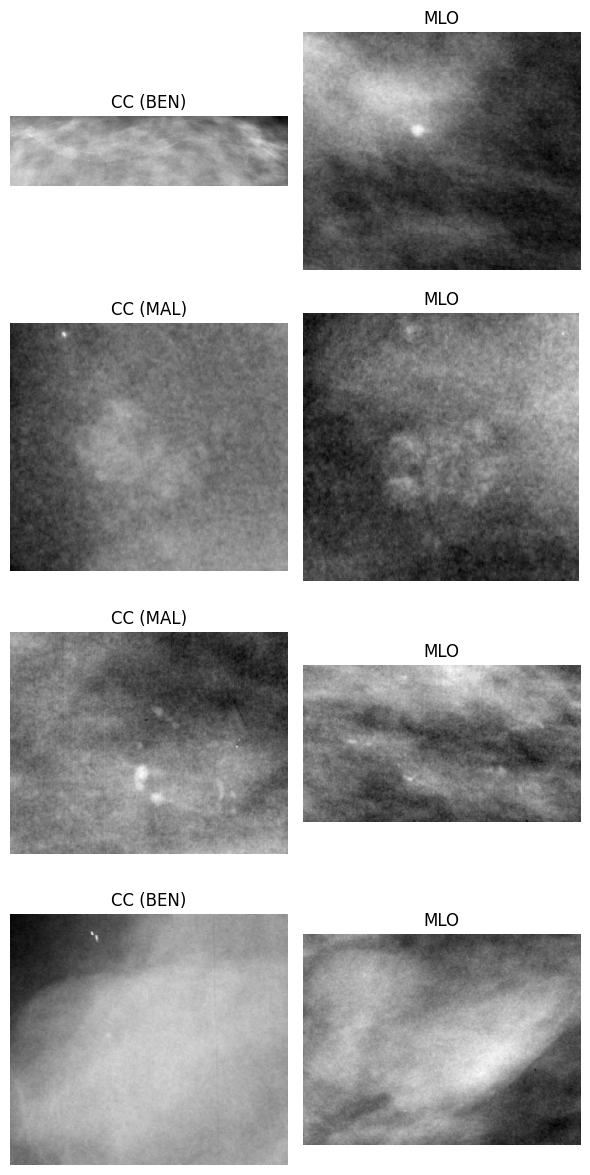

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage

sample = breast_df.sample(min(4, len(breast_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(len(sample), 2, figsize=(6, 3 * len(sample)))
for i, (_, row) in enumerate(sample.iterrows()):
    axes[i, 0].imshow(PILImage.open(row['cc_path']).convert('L'), cmap='gray')
    axes[i, 0].set_title(f"CC ({'MAL' if row['label'] else 'BEN'})"); axes[i, 0].axis('off')
    axes[i, 1].imshow(PILImage.open(row['mlo_path']).convert('L'), cmap='gray')
    axes[i, 1].set_title('MLO'); axes[i, 1].axis('off')
plt.tight_layout(); plt.show()


## Step 5 — Shared patient-level split
All three models train/validate/test on **this exact split** so the final comparison
is fair. 70/15/15, split by `patient_id` to prevent leakage.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, temp_idx = next(gss1.split(breast_df, groups=breast_df['patient_id']))
train_df = breast_df.iloc[train_idx].reset_index(drop=True)
temp_df = breast_df.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=RANDOM_STATE)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df['patient_id']))
val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

assert set(train_df.patient_id) & set(val_df.patient_id) == set()
assert set(train_df.patient_id) & set(test_df.patient_id) == set()
assert set(val_df.patient_id) & set(test_df.patient_id) == set()
print('Train / Val / Test pairs:', len(train_df), len(val_df), len(test_df))
print('Patient-level leakage check passed.')

# Patient -> split lookup, reused by Step 5b to fold in single-view-only images
# without breaking the patient-level split.
patient_split = {}
for pid in train_df['patient_id']:
    patient_split[pid] = 'train'
for pid in val_df['patient_id']:
    patient_split[pid] = 'val'
for pid in test_df['patient_id']:
    patient_split[pid] = 'test'


Train / Val / Test pairs: 1080 222 231
Patient-level leakage check passed.


### Step 5b — Larger single-view dataset (fixes Model A's underused data)
Model A doesn't need a CC/MLO pair, so it shouldn't be limited to the 1080 paired
breast-abnormality samples. This builds one row per **individual crop image**
(every CC and every MLO, matched or not) for patients already assigned to
train/val/test above — same split, same no-leakage guarantee, just more usable rows.

In [ ]:
single_view_df = case_df[case_df['patient_id'].isin(patient_split.keys())].copy()
single_view_df['split'] = single_view_df['patient_id'].map(patient_split)
single_view_df = single_view_df.dropna(subset=['image_path'])

print('Single-view dataset size (all individual crops):', len(single_view_df))
print(single_view_df.groupby('split')['label'].value_counts())
print(f"\n(vs {len(train_df) + len(val_df) + len(test_df)} paired samples available to Model A before this fix)")


Single-view dataset size (all individual crops): 3199
split  label
test   0         301
       1         185
train  0        1362
       1         889
val    0         248
       1         214
Name: count, dtype: int64

(vs 1533 paired samples available to Model A before this fix)


## Step 6 — Dataset & DataLoaders (paired CC/MLO crops)
CLAHE + grayscale->3ch + augmentation, same recipe as v2/v3. `WeightedRandomSampler`
balances every training mini-batch on top of the loss-level class weighting.

In [ ]:
!pip -q install opencv-python-headless

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image
import torchvision.transforms as T
import torchvision.models as models

class CLAHETransform:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    def __call__(self, pil_img):
        arr = np.array(pil_img)
        arr = self.clahe.apply(arr)
        return Image.fromarray(arr)

train_tf = T.Compose([
    CLAHETransform(),
    T.Grayscale(num_output_channels=3),
    # v2: scale narrowed from (0.85,1.0) to (0.95,1.0) - these are already tight
    # lesion crops, so aggressive cropping risked cutting the lesion out of frame.
    T.RandomResizedCrop(IMG_SIZE, scale=(0.95, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_tf = T.Compose([
    CLAHETransform(),
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class PairedMammoDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        cc = self.transform(Image.open(row['cc_path']).convert('L'))
        mlo = self.transform(Image.open(row['mlo_path']).convert('L'))
        label = torch.tensor(row['label'], dtype=torch.long)
        density = torch.tensor(row['density_label'], dtype=torch.long)
        subtlety = torch.tensor(row['subtlety_label'], dtype=torch.long)
        atype = torch.tensor(row['type_label'], dtype=torch.long)
        return cc, mlo, label, density, subtlety, atype

def make_loaders(train_df_f, val_df_f, test_df_f):
    train_ds = PairedMammoDataset(train_df_f, train_tf)
    val_ds = PairedMammoDataset(val_df_f, eval_tf)
    test_ds = PairedMammoDataset(test_df_f, eval_tf)

    labels_arr = train_df_f['label'].values
    class_counts = np.bincount(labels_arr, minlength=2)
    sample_weights = 1.0 / class_counts[labels_arr]
    sampler = WeightedRandomSampler(
        weights=torch.tensor(sample_weights, dtype=torch.double),
        num_samples=len(labels_arr), replacement=True,
    )
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| IMG_SIZE:', IMG_SIZE, '| batches (tr/val/test):',
      len(train_loader), len(val_loader), len(test_loader))

# --- Single-image dataset/loaders for Model A (Step 5b's larger, unpaired set) ---
class SingleImageDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = self.transform(Image.open(row['image_path']).convert('L'))
        label = torch.tensor(row['label'], dtype=torch.long)
        return img, label

def make_single_view_loaders(tr, va, te):
    tr_ds = SingleImageDataset(tr, train_tf)
    va_ds = SingleImageDataset(va, eval_tf)
    te_ds = SingleImageDataset(te, eval_tf)

    labels_arr = tr['label'].values
    class_counts = np.bincount(labels_arr, minlength=2)
    sample_weights = 1.0 / class_counts[labels_arr]
    sampler = WeightedRandomSampler(
        weights=torch.tensor(sample_weights, dtype=torch.double),
        num_samples=len(labels_arr), replacement=True)

    tr_loader = DataLoader(tr_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
    va_loader = DataLoader(va_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    te_loader = DataLoader(te_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return tr_loader, va_loader, te_loader


Device: cuda | IMG_SIZE: 224 | batches (tr/val/test): 23 5 5


## Step 7 — Shared training utilities
`FocalLoss` and class weights (from v2/v3), plus a generic epoch runner and TTA
predictor that both single-task (Model B) and multi-task (Model C) training loops
reuse via an `is_mtl` flag.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

def make_class_weights(labels):
    return torch.tensor(
        compute_class_weight('balanced', classes=np.array([0, 1]), y=labels), dtype=torch.float32
    ).to(device)

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, label_smoothing=0.05):
        super().__init__()
        self.alpha, self.gamma, self.label_smoothing = alpha, gamma, label_smoothing
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha,
                              label_smoothing=self.label_smoothing, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

class MultiTaskLoss(nn.Module):
    # v2 cut these to 0.15/0.15/0.10 and test AUC regressed (0.769 -> 0.734) vs the
    # original 0.3/0.3/0.2. v3 splits the difference rather than reverting fully -
    # the `ignore_index` masking of the "unknown" bucket (still in place) was the
    # part that mattered; the weight cut alone likely just starved the aux signal.
    LAMBDA_DENSITY, LAMBDA_SUBTLETY, LAMBDA_TYPE = 0.20, 0.20, 0.12
    def __init__(self, malignancy_alpha):
        super().__init__()
        self.malignancy_loss = FocalLoss(alpha=malignancy_alpha, gamma=2.0, label_smoothing=0.05)
        self.density_loss = nn.CrossEntropyLoss(label_smoothing=0.05, ignore_index=4)
        self.subtlety_loss = nn.CrossEntropyLoss(label_smoothing=0.05, ignore_index=5)
        self.type_loss = nn.CrossEntropyLoss(label_smoothing=0.05)
    def forward(self, outputs, malignancy, density, subtlety, atype):
        loss = self.malignancy_loss(outputs['malignancy'], malignancy)
        loss = loss + self.LAMBDA_DENSITY * self.density_loss(outputs['density'], density)
        loss = loss + self.LAMBDA_SUBTLETY * self.subtlety_loss(outputs['subtlety'], subtlety)
        loss = loss + self.LAMBDA_TYPE * self.type_loss(outputs['type'], atype)
        return loss

def set_encoder_trainable(model, unfreeze_prefixes):
    for name, param in model.encoder.named_parameters():
        param.requires_grad = any(name.startswith(p) for p in unfreeze_prefixes)

def run_epoch_dual(model, criterion, loader, train_mode, is_mtl, optimizer=None, accum_steps=1, scaler=None):
    model.train() if train_mode else model.eval()
    total_loss, probs_all, labels_all = 0.0, [], []
    torch.set_grad_enabled(train_mode)
    if train_mode:
        optimizer.zero_grad()
    n_batches = len(loader)
    for step, (cc, mlo, y, dens, subt, atype) in enumerate(loader):
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        dens, subt, atype = dens.to(device), subt.to(device), atype.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            out = model(cc, mlo)
            logits = out['malignancy'] if is_mtl else out
            loss = criterion(out, y, dens, subt, atype) if is_mtl else criterion(logits, y)
        if train_mode:
            scaler.scale(loss / accum_steps).backward()
            if (step + 1) % accum_steps == 0 or (step + 1) == n_batches:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad()
        total_loss += loss.item() * cc.size(0)
        probs_all.extend(torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy())
        labels_all.extend(y.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(labels_all, probs_all) if len(set(labels_all)) > 1 else float('nan')
    return avg_loss, auc

def predict_probs_tta_dual(model, loader, is_mtl):
    all_probs, all_labels = [], []
    model.eval()
    with torch.no_grad():
        for cc, mlo, y, dens, subt, atype in loader:
            cc, mlo = cc.to(device), mlo.to(device)
            out1 = model(cc, mlo); out2 = model(torch.flip(cc, dims=[3]), torch.flip(mlo, dims=[3]))
            l1 = out1['malignancy'] if is_mtl else out1
            l2 = out2['malignancy'] if is_mtl else out2
            p1 = torch.softmax(l1, dim=1)[:, 1]; p2 = torch.softmax(l2, dim=1)[:, 1]
            all_probs.extend(((p1 + p2) / 2).cpu().numpy())
            all_labels.extend(y.numpy())
    return np.array(all_probs), np.array(all_labels)

def train_dual_view(model_cls, is_mtl, tag, phase1_epochs=DUAL_PHASE1_EPOCHS,
                     phase2_max_epochs=DUAL_PHASE2_EPOCHS, patience=DUAL_PATIENCE):
    """Two-phase progressive-unfreezing trainer shared by Model B and Model C."""
    model = model_cls().to(device)
    class_w = make_class_weights(train_df['label'].values)
    criterion = MultiTaskLoss(malignancy_alpha=class_w) if is_mtl else FocalLoss(alpha=class_w, gamma=2.0, label_smoothing=0.05)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    best_val_auc, best_state = 0.0, None

    set_encoder_trainable(model, [])
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)
    for epoch in range(1, phase1_epochs + 1):
        tr_loss, tr_auc = run_epoch_dual(model, criterion, train_loader, True, is_mtl, optimizer, ACCUM_STEPS, scaler)
        va_loss, va_auc = run_epoch_dual(model, criterion, val_loader, False, is_mtl)
        print(f'[{tag} | Phase 1 | Epoch {epoch}] train_auc={tr_auc:.4f} val_auc={va_auc:.4f}')
        if va_auc > best_val_auc:
            best_val_auc = va_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    # v2: unfreeze layer2/3/4 (was layer3/4 only) so more of the backbone can
    # actually adapt to grayscale mammogram crops instead of relying on raw
    # ImageNet features for most of the network.
    set_encoder_trainable(model, UNFREEZE_PREFIXES)
    backbone_params = [p for n, p in model.named_parameters() if n.startswith('encoder') and p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if not n.startswith('encoder')]
    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': 1e-5}, {'params': head_params, 'lr': 3e-4}], weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    patience_ctr = 0
    for epoch in range(1, phase2_max_epochs + 1):
        tr_loss, tr_auc = run_epoch_dual(model, criterion, train_loader, True, is_mtl, optimizer, ACCUM_STEPS, scaler)
        va_loss, va_auc = run_epoch_dual(model, criterion, val_loader, False, is_mtl)
        scheduler.step(va_auc)
        print(f'[{tag} | Phase 2 | Epoch {epoch}] train_auc={tr_auc:.4f} val_auc={va_auc:.4f}')
        if va_auc > best_val_auc:
            best_val_auc, patience_ctr = va_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f'[{tag}] Early stopping at epoch {epoch}.')
                break

    model.load_state_dict(best_state)
    val_probs, val_labels_arr = predict_probs_tta_dual(model, val_loader, is_mtl)
    fpr, tpr, thresholds = roc_curve(val_labels_arr, val_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    test_probs, test_labels_arr = predict_probs_tta_dual(model, test_loader, is_mtl)
    test_auc = roc_auc_score(test_labels_arr, test_probs)
    test_preds = (test_probs >= threshold).astype(int)
    test_acc = (test_preds == test_labels_arr).mean()
    return {'tag': tag, 'model': model, 'threshold': threshold, 'test_auc': test_auc,
            'test_acc': test_acc, 'test_probs': test_probs, 'test_labels': test_labels_arr,
            'test_preds': test_preds, 'is_mtl': is_mtl,
            'val_auc': roc_auc_score(val_labels_arr, val_probs), 'val_probs': val_probs,
            'val_labels': val_labels_arr}

def run_bagged_dual(model_cls, is_mtl, tag, pool_df, held_out_test_df, n_folds=N_BAG_FOLDS):
    """v4: replaces a single 70/15 split with n_folds patient-grouped, stratified
    folds carved from pool_df (= original train_df + val_df). held_out_test_df is
    NEVER used for training or fold selection in any fold - only for the final
    bagged prediction. Returns bagged (averaged) test predictions plus a proper
    out-of-fold (OOF) threshold estimated across the whole pool."""
    global train_loader, val_loader, test_loader
    skf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    pool_df = pool_df.reset_index(drop=True)
    oof_probs = np.zeros(len(pool_df))
    oof_filled = np.zeros(len(pool_df), dtype=bool)
    test_prob_accum = np.zeros(len(held_out_test_df))
    fold_models, fold_val_aucs, fold_test_aucs = [], [], []

    splits = skf.split(pool_df, y=pool_df['label'], groups=pool_df['patient_id'])
    for fold_id, (tr_idx, va_idx) in enumerate(splits):
        fold_train_df = pool_df.iloc[tr_idx].reset_index(drop=True)
        fold_val_df = pool_df.iloc[va_idx].reset_index(drop=True)
        train_loader, val_loader, test_loader = make_loaders(fold_train_df, fold_val_df, held_out_test_df)
        r = train_dual_view(model_cls, is_mtl, f'{tag} fold{fold_id}')
        oof_probs[va_idx] = r['val_probs']
        oof_filled[va_idx] = True
        test_prob_accum += r['test_probs']
        fold_val_aucs.append(r['val_auc']); fold_test_aucs.append(r['test_auc'])
        fold_models.append(r['model'].cpu())
        print(f'[{tag}] fold {fold_id}: val_auc={r["val_auc"]:.4f}  test_auc={r["test_auc"]:.4f}')

    assert oof_filled.all(), 'every pool row should land in exactly one fold validation set'
    oof_labels = pool_df['label'].values
    bagged_test_probs = test_prob_accum / n_folds
    fpr, tpr, thresholds = roc_curve(oof_labels, oof_probs)
    oof_threshold = thresholds[np.argmax(tpr - fpr)]
    test_labels_arr = held_out_test_df['label'].values
    bagged_test_auc = roc_auc_score(test_labels_arr, bagged_test_probs)
    bagged_test_preds = (bagged_test_probs >= oof_threshold).astype(int)
    bagged_test_acc = (bagged_test_preds == test_labels_arr).mean()

    best_fold_idx = int(np.argmax(fold_val_aucs))
    best_model = fold_models[best_fold_idx].to(device)  # kept on-device for Grad-CAM later
    print(f'[{tag}] bagged test_auc={bagged_test_auc:.4f}  bagged test_acc={bagged_test_acc:.4f} '
          f'(fold test_auc range {min(fold_test_aucs):.4f}-{max(fold_test_aucs):.4f})')

    return {'tag': tag, 'model': best_model, 'fold_models': fold_models, 'threshold': oof_threshold,
            'test_auc': bagged_test_auc, 'test_acc': bagged_test_acc, 'test_probs': bagged_test_probs,
            'test_labels': test_labels_arr, 'test_preds': bagged_test_preds, 'is_mtl': is_mtl,
            'val_auc': roc_auc_score(oof_labels, oof_probs), 'val_probs': oof_probs, 'val_labels': oof_labels}


## Model A — Single-view baselines (CC-only, MLO-only)
v2: trained on Step 5b's larger single-image dataset (every individual crop for
patients in the shared split, not just the 1080 paired ones). v4: bagged across
`N_BAG_FOLDS` patient-grouped folds by default, same as Model B/C below.

In [ ]:
class SingleViewNet(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        backbone = models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        in_feat = backbone.fc.in_features
        backbone.fc = nn.Linear(in_feat, num_classes)
        self.net = backbone
    def forward(self, x):
        return self.net(x)

def predict_tta_single(m, loader):
    """Horizontal-flip TTA prediction, kept out of the per-epoch training loop."""
    m.eval()
    probs_all, labels_all = [], []
    with torch.no_grad():
        for img, y in loader:
            img = img.to(device)
            p1 = torch.softmax(m(img), dim=1)[:, 1]
            p2 = torch.softmax(m(torch.flip(img, dims=[3])), dim=1)[:, 1]
            probs_all.extend(((p1 + p2) / 2).cpu().numpy())
            labels_all.extend(y.numpy())
    return np.array(probs_all), np.array(labels_all)

def train_single_view(tr_df, va_df, te_df, tag, epochs=SINGLE_VIEW_EPOCHS):
    tr_loader, va_loader, te_loader = make_single_view_loaders(tr_df, va_df, te_df)
    print(f'[{tag}] train/val/test images: {len(tr_loader.dataset)}/{len(va_loader.dataset)}/{len(te_loader.dataset)}')

    m = SingleViewNet().to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss(weight=make_class_weights(tr_df['label'].values), label_smoothing=0.05)
    best_auc, best_state = 0.0, None

    def epoch_pass(loader, is_train):
        m.train() if is_train else m.eval()
        torch.set_grad_enabled(is_train)
        probs_all, labels_all = [], []
        for img, y in loader:
            img, y = img.to(device), y.to(device)
            if is_train:
                opt.zero_grad()
            out = m(img)
            loss = crit(out, y)
            if is_train:
                loss.backward(); opt.step()
            probs_all.extend(torch.softmax(out, dim=1)[:, 1].detach().cpu().numpy())
            labels_all.extend(y.cpu().numpy())
        auc = roc_auc_score(labels_all, probs_all) if len(set(labels_all)) > 1 else float('nan')
        return auc, np.array(probs_all), np.array(labels_all)

    for ep in range(1, epochs + 1):
        epoch_pass(tr_loader, True)
        va_auc, _, _ = epoch_pass(va_loader, False)
        print(f'[{tag} | Epoch {ep}] val_auc={va_auc:.4f}')
        if va_auc > best_auc:
            best_auc = va_auc
            best_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}

    m.load_state_dict(best_state)
    va_probs, va_labels = predict_tta_single(m, va_loader)
    fpr, tpr, thresholds = roc_curve(va_labels, va_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    te_probs, te_labels = predict_tta_single(m, te_loader)
    te_preds = (te_probs >= threshold).astype(int)
    te_acc = (te_preds == te_labels).mean()
    te_auc = roc_auc_score(te_labels, te_probs)
    return {'tag': tag, 'model': m, 'test_auc': te_auc, 'test_acc': te_acc,
            'test_probs': te_probs, 'test_labels': te_labels, 'test_preds': te_preds,
            'val_auc': roc_auc_score(va_labels, va_probs), 'val_probs': va_probs,
            'val_labels': va_labels, 'threshold': threshold}

def run_bagged_single(view_key, pool_df, held_out_test_df, n_folds=N_BAG_FOLDS):
    """v4: same patient-grouped bagging idea as run_bagged_dual, for a single-view
    model. held_out_test_df here is test_df's own (cc_path/mlo_path) column, renamed
    to image_path, so the bagged prediction lands on the SAME 231 test pairs used by
    B/C - not Model A's own larger, differently-sized single-view test split."""
    skf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    pool_df = pool_df.reset_index(drop=True)
    oof_probs = np.zeros(len(pool_df))
    oof_filled = np.zeros(len(pool_df), dtype=bool)
    test_prob_accum = np.zeros(len(held_out_test_df))
    fold_models, fold_val_aucs, fold_test_aucs = [], [], []

    splits = skf.split(pool_df, y=pool_df['label'], groups=pool_df['patient_id'])
    for fold_id, (tr_idx, va_idx) in enumerate(splits):
        fold_train_df = pool_df.iloc[tr_idx].reset_index(drop=True)
        fold_val_df = pool_df.iloc[va_idx].reset_index(drop=True)
        r = train_single_view(fold_train_df, fold_val_df, held_out_test_df, f'{view_key} fold{fold_id}')
        oof_probs[va_idx] = r['val_probs']
        oof_filled[va_idx] = True
        test_prob_accum += r['test_probs']
        fold_val_aucs.append(r['val_auc']); fold_test_aucs.append(r['test_auc'])
        fold_models.append(r['model'].cpu())
        print(f'[{view_key}] fold {fold_id}: val_auc={r["val_auc"]:.4f}  test_auc={r["test_auc"]:.4f}')

    assert oof_filled.all()
    oof_labels = pool_df['label'].values
    bagged_test_probs = test_prob_accum / n_folds
    fpr, tpr, thresholds = roc_curve(oof_labels, oof_probs)
    oof_threshold = thresholds[np.argmax(tpr - fpr)]
    test_labels_arr = held_out_test_df['label'].values
    bagged_test_auc = roc_auc_score(test_labels_arr, bagged_test_probs)
    bagged_test_preds = (bagged_test_probs >= oof_threshold).astype(int)
    bagged_test_acc = (bagged_test_preds == test_labels_arr).mean()
    best_fold_idx = int(np.argmax(fold_val_aucs))
    print(f'[{view_key}] bagged test_auc={bagged_test_auc:.4f}  bagged test_acc={bagged_test_acc:.4f} '
          f'(fold test_auc range {min(fold_test_aucs):.4f}-{max(fold_test_aucs):.4f})')

    return {'tag': view_key, 'model': fold_models[best_fold_idx].to(device), 'fold_models': fold_models,
            'threshold': oof_threshold, 'test_auc': bagged_test_auc, 'test_acc': bagged_test_acc,
            'test_probs': bagged_test_probs, 'test_labels': test_labels_arr, 'test_preds': bagged_test_preds,
            'val_auc': roc_auc_score(oof_labels, oof_probs), 'val_probs': oof_probs, 'val_labels': oof_labels}

if RUN_BAGGED_ENSEMBLE:
    # Ensemble alignment: pool and evaluate directly on the breast-pair dataframes'
    # own cc_path/mlo_path columns (renamed to image_path), NOT single_view_df's
    # larger, unpaired split - this keeps every model's test predictions on the
    # exact same 231 held-out pairs for a fair, aligned final ensemble.
    cc_pool = pd.concat([train_df, val_df], ignore_index=True).rename(columns={'cc_path': 'image_path'})
    mlo_pool = pd.concat([train_df, val_df], ignore_index=True).rename(columns={'mlo_path': 'image_path'})
    cc_test_aligned = test_df.rename(columns={'cc_path': 'image_path'})
    mlo_test_aligned = test_df.rename(columns={'mlo_path': 'image_path'})
    cc_result = run_bagged_single('CC', cc_pool, cc_test_aligned)
    mlo_result = run_bagged_single('MLO', mlo_pool, mlo_test_aligned)
else:
    cc_view_df = single_view_df[single_view_df['image view'] == 'CC']
    mlo_view_df = single_view_df[single_view_df['image view'] == 'MLO']
    cc_result = train_single_view(cc_view_df[cc_view_df.split == 'train'], cc_view_df[cc_view_df.split == 'val'],
                                   cc_view_df[cc_view_df.split == 'test'], 'CC')
    mlo_result = train_single_view(mlo_view_df[mlo_view_df.split == 'train'], mlo_view_df[mlo_view_df.split == 'val'],
                                    mlo_view_df[mlo_view_df.split == 'test'], 'MLO')

print('\nCC-only  : Test AUC =', cc_result['test_auc'], '| Test Acc =', cc_result['test_acc'])
print('MLO-only : Test AUC =', mlo_result['test_auc'], '| Test Acc =', mlo_result['test_acc'])


[CC fold0] train/val/test images: 1035/267/231
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 147MB/s]


[CC fold0 | Epoch 1] val_auc=0.7021
[CC fold0 | Epoch 2] val_auc=0.7500
[CC fold0 | Epoch 3] val_auc=0.8064
[CC fold0 | Epoch 4] val_auc=0.7916
[CC fold0 | Epoch 5] val_auc=0.7854
[CC fold0 | Epoch 6] val_auc=0.8295
[CC fold0 | Epoch 7] val_auc=0.7978
[CC fold0 | Epoch 8] val_auc=0.7970
[CC fold0 | Epoch 9] val_auc=0.8253
[CC fold0 | Epoch 10] val_auc=0.8178
[CC fold0 | Epoch 11] val_auc=0.8204
[CC fold0 | Epoch 12] val_auc=0.8061
[CC fold0 | Epoch 13] val_auc=0.8069
[CC fold0 | Epoch 14] val_auc=0.8262
[CC fold0 | Epoch 15] val_auc=0.8300
[CC fold0 | Epoch 16] val_auc=0.8407
[CC fold0 | Epoch 17] val_auc=0.8416
[CC fold0 | Epoch 18] val_auc=0.8493
[CC fold0 | Epoch 19] val_auc=0.8424
[CC fold0 | Epoch 20] val_auc=0.8454
[CC] fold 0: val_auc=0.8520  test_auc=0.7545
[CC fold1] train/val/test images: 1056/246/231
[CC fold1 | Epoch 1] val_auc=0.6182
[CC fold1 | Epoch 2] val_auc=0.6249
[CC fold1 | Epoch 3] val_auc=0.7025
[CC fold1 | Epoch 4] val_auc=0.6875
[CC fold1 | Epoch 5] val_auc=0.69

## Model B — Dual-view cross-attention (single-task)
Weight-shared ResNet50 encoders for CC/MLO, fused with a cross-view attention block,
one malignancy head. (This is the v1/v2 architecture.)

In [ ]:
class CrossViewAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.q = nn.Linear(dim, dim); self.k = nn.Linear(dim, dim); self.v = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim); self.norm = nn.LayerNorm(dim); self.scale = dim ** -0.5
    def forward(self, a, b):
        q = self.q(a).unsqueeze(1); k = self.k(b).unsqueeze(1); v = self.v(b).unsqueeze(1)
        attn = torch.softmax((q @ k.transpose(-2, -1)) * self.scale, dim=-1)
        out = self.out_proj((attn @ v).squeeze(1))
        return self.norm(a + out)

class DualViewMammoNet(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        backbone = models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        self.feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.encoder = backbone
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.cc_to_mlo = CrossViewAttention(self.feat_dim)
        self.mlo_to_cc = CrossViewAttention(self.feat_dim)
        self.classifier = nn.Sequential(
            nn.Linear(self.feat_dim * 4, 256), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(256, num_classes))
    def forward(self, cc_img, mlo_img):
        f_cc = self.encoder(cc_img); f_mlo = self.encoder(mlo_img)
        cc_attended = self.cc_to_mlo(f_cc, f_mlo); mlo_attended = self.mlo_to_cc(f_mlo, f_cc)
        fused = torch.cat([f_cc, f_mlo, cc_attended, mlo_attended], dim=1)
        return self.classifier(fused)

result_B = (run_bagged_dual(DualViewMammoNet, is_mtl=False, tag='Model B (dual-view)',
                             pool_df=pd.concat([train_df, val_df], ignore_index=True), held_out_test_df=test_df)
            if RUN_BAGGED_ENSEMBLE else
            train_dual_view(DualViewMammoNet, is_mtl=False, tag='Model B (dual-view)'))
print('\nModel B — Test AUC:', result_B['test_auc'], '| Test Acc:', result_B['test_acc'])


[Model B (dual-view) fold0 | Phase 1 | Epoch 1] train_auc=0.4861 val_auc=0.7259
[Model B (dual-view) fold0 | Phase 1 | Epoch 2] train_auc=0.5510 val_auc=0.7035
[Model B (dual-view) fold0 | Phase 2 | Epoch 1] train_auc=0.5676 val_auc=0.7121
[Model B (dual-view) fold0 | Phase 2 | Epoch 2] train_auc=0.6881 val_auc=0.7325
[Model B (dual-view) fold0 | Phase 2 | Epoch 3] train_auc=0.6760 val_auc=0.7490
[Model B (dual-view) fold0 | Phase 2 | Epoch 4] train_auc=0.7076 val_auc=0.7561
[Model B (dual-view) fold0 | Phase 2 | Epoch 5] train_auc=0.6834 val_auc=0.7614
[Model B (dual-view) fold0 | Phase 2 | Epoch 6] train_auc=0.7206 val_auc=0.7695
[Model B (dual-view) fold0 | Phase 2 | Epoch 7] train_auc=0.7678 val_auc=0.7820
[Model B (dual-view) fold0 | Phase 2 | Epoch 8] train_auc=0.7621 val_auc=0.7743
[Model B (dual-view) fold0 | Phase 2 | Epoch 9] train_auc=0.7881 val_auc=0.7915
[Model B (dual-view) fold0 | Phase 2 | Epoch 10] train_auc=0.7750 val_auc=0.7933
[Model B (dual-view) fold0 | Phase 2 | 

## Model C — Dual-view multi-task learning (MTL)
Same cross-attention fusion, plus auxiliary heads for breast density, subtlety, and
abnormality type — regularizing the shared representation. (This is the v3 architecture.)
v4: bagged across `N_BAG_FOLDS` folds via the same `run_bagged_dual` helper as Model B
(replaces the old ad-hoc, Model-C-only CV branch from earlier versions).

In [ ]:
class DualViewMammoNetMTL(nn.Module):
    def __init__(self, pretrained=True, n_density=N_DENSITY_CLASSES, n_subtlety=N_SUBTLETY_CLASSES, n_type=N_TYPE_CLASSES):
        super().__init__()
        backbone = models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        self.feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.encoder = backbone
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.cc_to_mlo = CrossViewAttention(self.feat_dim)
        self.mlo_to_cc = CrossViewAttention(self.feat_dim)
        fused_dim = self.feat_dim * 4
        self.trunk = nn.Sequential(nn.Linear(fused_dim, 256), nn.ReLU(inplace=True), nn.Dropout(0.5))
        self.malignancy_head = nn.Linear(256, 2)
        self.density_head = nn.Linear(256, n_density)
        self.subtlety_head = nn.Linear(256, n_subtlety)
        self.type_head = nn.Linear(256, n_type)
    def forward(self, cc_img, mlo_img):
        f_cc = self.encoder(cc_img); f_mlo = self.encoder(mlo_img)
        cc_attended = self.cc_to_mlo(f_cc, f_mlo); mlo_attended = self.mlo_to_cc(f_mlo, f_cc)
        fused = torch.cat([f_cc, f_mlo, cc_attended, mlo_attended], dim=1)
        shared = self.trunk(fused)
        return {'malignancy': self.malignancy_head(shared), 'density': self.density_head(shared),
                'subtlety': self.subtlety_head(shared), 'type': self.type_head(shared)}

result_C = (run_bagged_dual(DualViewMammoNetMTL, is_mtl=True, tag='Model C (dual-view MTL)',
                             pool_df=pd.concat([train_df, val_df], ignore_index=True), held_out_test_df=test_df)
            if RUN_BAGGED_ENSEMBLE else
            train_dual_view(DualViewMammoNetMTL, is_mtl=True, tag='Model C (dual-view MTL)'))
print('\nModel C — Test AUC:', result_C['test_auc'], '| Test Acc:', result_C['test_acc'])


[Model C (dual-view MTL) fold0 | Phase 1 | Epoch 1] train_auc=0.5454 val_auc=0.6376
[Model C (dual-view MTL) fold0 | Phase 1 | Epoch 2] train_auc=0.5607 val_auc=0.6788
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 1] train_auc=0.5745 val_auc=0.6819
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 2] train_auc=0.6755 val_auc=0.6914
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 3] train_auc=0.6330 val_auc=0.7075
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 4] train_auc=0.6620 val_auc=0.7445
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 5] train_auc=0.7300 val_auc=0.7324
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 6] train_auc=0.7299 val_auc=0.7682
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 7] train_auc=0.7173 val_auc=0.7694
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 8] train_auc=0.7430 val_auc=0.7601
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 9] train_auc=0.7449 val_auc=0.7923
[Model C (dual-view MTL) fold0 | Phase 2 | Epoch 10] train_auc=0.7469 val_au

## Ensemble
A **weighted** average of all four models (CC, MLO, B, C), weighted by each model's own
validation AUC (models that separate the classes better get more say), with its own
decision threshold tuned on validation rather than reusing any single model's threshold.

With `RUN_BAGGED_ENSEMBLE=True` (default), every model's `test_probs`/`val_probs` are
already the bagged, `test_df`-aligned predictions produced above, so they can be blended
directly. The fallback (`RUN_BAGGED_ENSEMBLE=False`) path still needs to realign Model A's
single-split predictions onto `val_df`/`test_df`, since its own val/test splits are a
different, larger set of individual crops.

In [ ]:
def predict_single_view(model, loader):
    model.eval()
    probs_all, labels_all = [], []
    with torch.no_grad():
        for img, y in loader:
            img = img.to(device)
            p1 = torch.softmax(model(img), dim=1)[:, 1]
            p2 = torch.softmax(model(torch.flip(img, dims=[3])), dim=1)[:, 1]
            probs_all.extend(((p1 + p2) / 2).cpu().numpy())
            labels_all.extend(y.numpy())
    return np.array(probs_all), np.array(labels_all)

def aligned_single_view_probs(model, df, path_col):
    ds = SingleImageDataset(df.rename(columns={path_col: 'image_path'}), eval_tf)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return predict_single_view(model, loader)

if RUN_BAGGED_ENSEMBLE:
    # cc_result / mlo_result were already trained + evaluated directly on val_df/test_df's
    # own cc_path/mlo_path (see run_bagged_single above), and are already bagged across
    # folds - nothing to regenerate, just use them as-is.
    cc_val_probs, mlo_val_probs = cc_result['val_probs'], mlo_result['val_probs']
    cc_test_probs, mlo_test_probs = cc_result['test_probs'], mlo_result['test_probs']
    val_labels_aligned = result_B['val_labels']   # pool labels, same row order across all 4 models
    test_labels_aligned = test_df['label'].values
else:
    # Fallback path: cc_result/mlo_result's own val/test sets are a different, larger,
    # unaligned set of individual crops - regenerate predictions on the exact paired
    # val_df/test_df so every model's predictions line up sample-for-sample.
    cc_val_probs, _ = aligned_single_view_probs(cc_result['model'], val_df, 'cc_path')
    cc_test_probs, _ = aligned_single_view_probs(cc_result['model'], test_df, 'cc_path')
    mlo_val_probs, _ = aligned_single_view_probs(mlo_result['model'], val_df, 'mlo_path')
    mlo_test_probs, _ = aligned_single_view_probs(mlo_result['model'], test_df, 'mlo_path')
    val_labels_aligned = val_df['label'].values
    test_labels_aligned = test_df['label'].values

component_val_probs = {'CC': cc_val_probs, 'MLO': mlo_val_probs, 'B': result_B['val_probs'], 'C': result_C['val_probs']}
component_test_probs = {'CC': cc_test_probs, 'MLO': mlo_test_probs, 'B': result_B['test_probs'], 'C': result_C['test_probs']}

# Weight each model by how well it separates classes on its *own* validation predictions.
component_val_auc = {name: roc_auc_score(val_labels_aligned, probs) for name, probs in component_val_probs.items()}
raw_weights = {name: max(auc - 0.5, 0.01) for name, auc in component_val_auc.items()}
weight_sum = sum(raw_weights.values())
weights = {name: w / weight_sum for name, w in raw_weights.items()}

print('Per-model validation AUC:', {k: round(v, 4) for k, v in component_val_auc.items()})
print('Ensemble weights:', {k: round(v, 4) for k, v in weights.items()})

ensemble_val_probs = sum(weights[name] * component_val_probs[name] for name in weights)
ensemble_probs = sum(weights[name] * component_test_probs[name] for name in weights)
ensemble_labels = test_labels_aligned

fpr, tpr, thresholds = roc_curve(val_labels_aligned, ensemble_val_probs)
ensemble_threshold = thresholds[np.argmax(tpr - fpr)]

ensemble_auc = roc_auc_score(ensemble_labels, ensemble_probs)
ensemble_preds = (ensemble_probs >= ensemble_threshold).astype(int)
ensemble_acc = (ensemble_preds == ensemble_labels).mean()

print('\nEnsemble Test AUC:', ensemble_auc)
print('Ensemble Test Accuracy:', ensemble_acc)
print(classification_report(ensemble_labels, ensemble_preds, target_names=['BENIGN', 'MALIGNANT']))


Per-model validation AUC: {'CC': np.float64(0.8061), 'MLO': np.float64(0.796), 'B': np.float64(0.8045), 'C': np.float64(0.7943)}
Ensemble weights: {'CC': np.float64(0.2549), 'MLO': np.float64(0.2465), 'B': np.float64(0.2536), 'C': np.float64(0.2451)}

Ensemble Test AUC: 0.8176085568326947
Ensemble Test Accuracy: 0.7575757575757576
              precision    recall  f1-score   support

      BENIGN       0.81      0.79      0.80       144
   MALIGNANT       0.67      0.70      0.69        87

    accuracy                           0.76       231
   macro avg       0.74      0.75      0.74       231
weighted avg       0.76      0.76      0.76       231



## Comparative analysis
AUC, accuracy, precision, recall (sensitivity), specificity, and F1 for every model
trained above, side by side.

In [ ]:
best_dual = result_C if result_C['test_auc'] >= result_B['test_auc'] else result_B
best_dual_name = 'Model C (MTL)' if best_dual is result_C else 'Model B (dual-view)'
print('Best dual-view model (used for Grad-CAM below):', best_dual_name)

def full_metrics(name, labels, preds, probs):
    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) else float('nan')
    precision = tp / (tp + fp) if (tp + fp) else float('nan')
    f1 = 2 * precision * sensitivity / (precision + sensitivity) if (precision + sensitivity) else float('nan')
    acc = (preds == labels).mean()
    auc = roc_auc_score(labels, probs) if len(set(labels)) > 1 else float('nan')
    return {'Model': name, 'AUC': auc, 'Accuracy': acc, 'Precision': precision,
            'Sensitivity (Recall)': sensitivity, 'Specificity': specificity, 'F1': f1}

rows = [
    full_metrics('A - CC only', cc_result['test_labels'], cc_result['test_preds'], cc_result['test_probs']),
    full_metrics('A - MLO only', mlo_result['test_labels'], mlo_result['test_preds'], mlo_result['test_probs']),
    full_metrics('B - Dual-view', result_B['test_labels'], result_B['test_preds'], result_B['test_probs']),
    full_metrics('C - Dual-view MTL', result_C['test_labels'], result_C['test_preds'], result_C['test_probs']),
    full_metrics('Ensemble', ensemble_labels, ensemble_preds, ensemble_probs),
]
comparison_df = pd.DataFrame(rows).round(4)
comparison_df


Best dual-view model (used for Grad-CAM below): Model B (dual-view)


,Model,AUC,Accuracy,Precision,Sensitivity (Recall),Specificity,F1
0,A - CC only,0.7898,0.7056,0.5841,0.7586,0.6736,0.6600
1,A - MLO only,0.7939,0.7576,0.6598,0.7356,0.7708,0.6957
2,B - Dual-view,0.7956,0.7316,0.6344,0.6782,0.7639,0.6556
3,C - Dual-view MTL,0.7850,0.7100,0.6471,0.5057,0.8333,0.5677
4,Ensemble,0.8176,0.7576,0.6703,0.7011,0.7917,0.6854


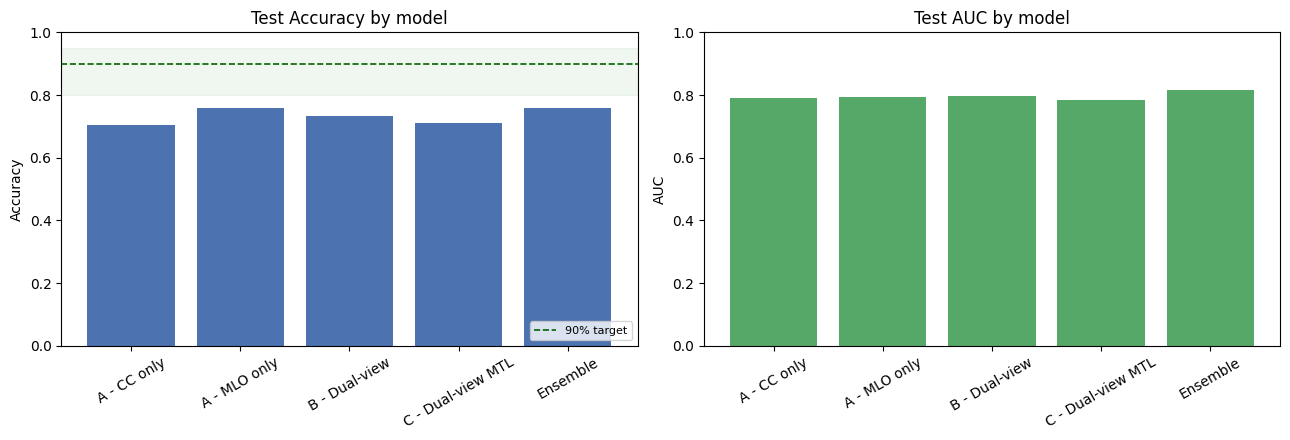

Best model by AUC: Ensemble


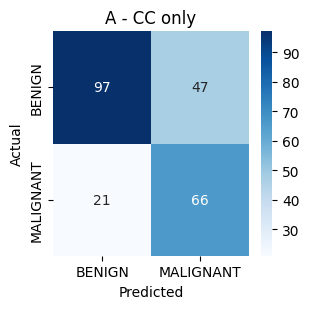

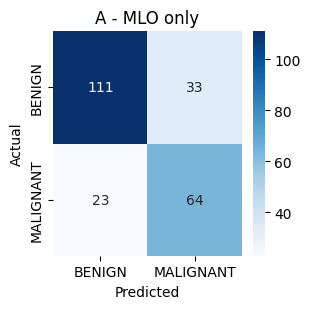

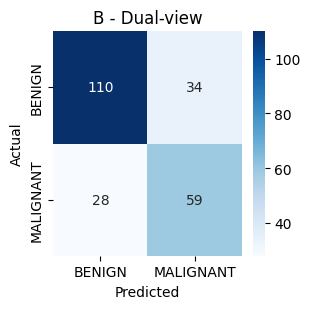

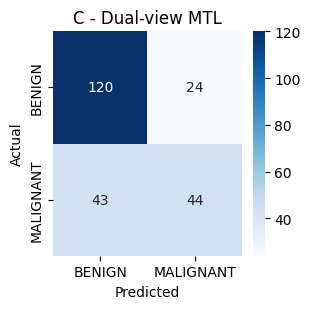

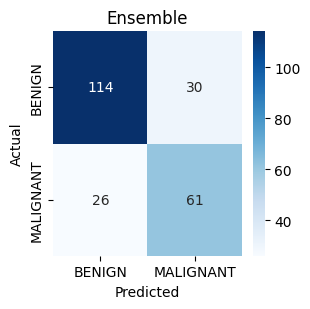

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(comparison_df['Model'], comparison_df['Accuracy'], color='#4C72B0')
axes[0].axhline(0.90, color='darkgreen', linestyle='--', linewidth=1.2, label='90% target')
axes[0].axhspan(0.80, 0.95, color='green', alpha=0.06)
axes[0].legend(loc='lower right', fontsize=8)
axes[0].set_title('Test Accuracy by model'); axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(comparison_df['Model'], comparison_df['AUC'], color='#55A868')
axes[1].set_title('Test AUC by model'); axes[1].set_ylabel('AUC'); axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

import seaborn as sns
best_row = comparison_df.loc[comparison_df['AUC'].idxmax(), 'Model']
print('Best model by AUC:', best_row)

for name, labels, preds in [
    ('A - CC only', cc_result['test_labels'], cc_result['test_preds']),
    ('A - MLO only', mlo_result['test_labels'], mlo_result['test_preds']),
    ('B - Dual-view', result_B['test_labels'], result_B['test_preds']),
    ('C - Dual-view MTL', result_C['test_labels'], result_C['test_preds']),
    ('Ensemble', ensemble_labels, ensemble_preds),
]:
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(3.2, 3.2))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['BENIGN', 'MALIGNANT'], yticklabels=['BENIGN', 'MALIGNANT'])
    plt.title(name); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()


## Grad-CAM (explainability)
Runs on whichever of Model B / Model C scored higher (`best_dual`), showing which regions
of the CC crop drove the malignant prediction, with the paired MLO crop held fixed.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 83.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


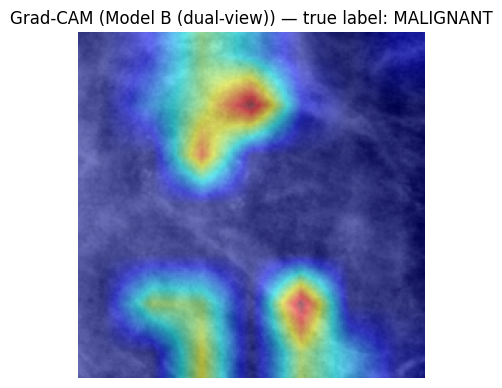

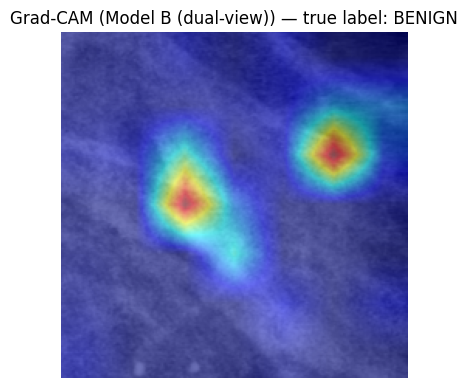

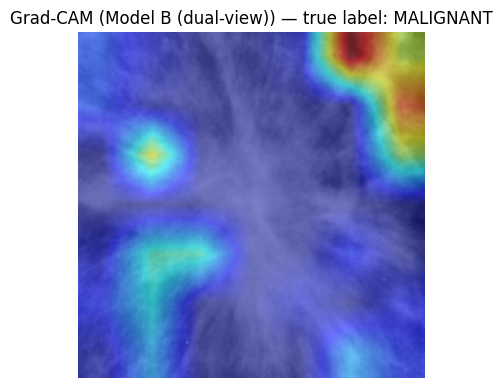

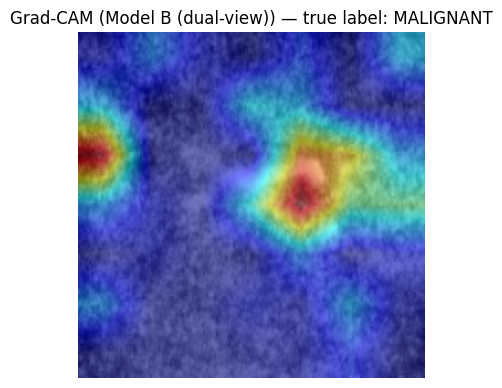

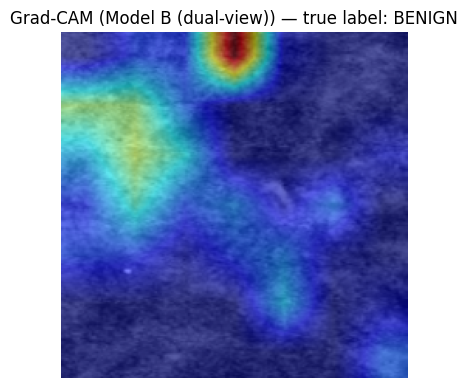

In [ ]:
!pip -q install grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

cam_model = best_dual['model']
cam_model.eval()
cam_is_mtl = best_dual['is_mtl']

class WrapperForCAM(nn.Module):
    def __init__(self, base_model, fixed_mlo, is_mtl):
        super().__init__()
        self.base_model = base_model
        self.fixed_mlo = fixed_mlo
        self.is_mtl = is_mtl
    def forward(self, cc):
        out = self.base_model(cc, self.fixed_mlo.expand(cc.size(0), -1, -1, -1))
        return out['malignancy'] if self.is_mtl else out

num_cam_images_to_show = 10

for i, (sample_cc, sample_mlo, sample_label, sample_dens, sample_subt, sample_type) in enumerate(test_loader):
    if i >= num_cam_images_to_show:
        break
    sample_cc, sample_mlo = sample_cc.to(device), sample_mlo.to(device)

    input_for_cam = sample_cc[:1].detach().clone(); input_for_cam.requires_grad_(True)
    fixed_mlo_for_wrapper = sample_mlo[:1].detach().clone(); fixed_mlo_for_wrapper.requires_grad_(True)
    wrapped = WrapperForCAM(cam_model, fixed_mlo_for_wrapper, cam_is_mtl)

    with torch.enable_grad():
        cam = GradCAM(model=wrapped, target_layers=[wrapped.base_model.encoder.layer4[-1]])
        grayscale_cam = cam(input_tensor=input_for_cam)[0]

    img_np = sample_cc[0].permute(1, 2, 0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())
    vis = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(vis)
    plt.title(f'Grad-CAM ({best_dual_name}) — true label: {"MALIGNANT" if sample_label[0]==1 else "BENIGN"}')
    plt.axis('off')
    plt.show()
